# HW4 — DFA: The Factors
**FINM 36700: Portfolio and Risk Management**
**Group Members: Ying Ding, Jiarui Feng, Hoang Pham, Nikita Rodin**

This notebook covers Sections 2 and 3 of the DFA case: *The Factors* (questions 1–5) and *CAPM* (questions 1–5).

Data, from the course [Box folder](https://uchicago.box.com/s/w3oqz9iy0kav3n3l4pa04p6etndo2ez2):
- `dfa_analysis_data.xlsx`, sheet `factors`: monthly Fama-French factors `Mkt-RF`, `SMB`, `HML` (already excess returns) and `RF`, July 1926 to August 2026 (Ken French Data Library). `RF` is used only in Section 3.
- Sheet `portfolios (total returns)`: 25 value-weighted portfolios sorted by size and book-to-market, monthly total returns. Used in Section 3.

**AI disclosure.** Content drafted with AI assistance and reviewed by the group for accuracy.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import statsmodels.api as sm
from scipy.stats import chi2

plt.rcParams.update({'figure.figsize': (9, 5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
pd.set_option('display.max_columns', 20)

DFA_FILE = Path('dfa_analysis_data.xlsx')
OUTPUT = Path('results')
OUTPUT.mkdir(exist_ok=True)

ANN = 12   # monthly data
FACTORS = ['Mkt-RF', 'SMB', 'HML']

# Section 2 — The Factors

## Data and notation

- `Mkt-RF`: market excess return. `SMB`: small minus big (size). `HML`: high minus low book-to-market (value). All three are long-short or excess returns, so they need no further adjustment.
- Annualization: mean $\times 12$, volatility $\times\sqrt{12}$, Sharpe ratio $\times\sqrt{12}$. VaR(.05) is the monthly 5th percentile and is not annualized.

Subsamples: 1926-07 to 1980-12, 1981-01 to 2001-12, and 2002-01 to 2026-08 (after the case).

In [2]:
factors = pd.read_excel(DFA_FILE, sheet_name='factors', index_col='Date')
factors.index = pd.to_datetime(factors.index)
factors = factors.sort_index()[FACTORS]

SAMPLES = {'1926-1980': ('1926-07', '1980-12'), '1981-2001': ('1981-01', '2001-12'),
           '2002-2026': ('2002-01', '2026-08')}

def sample(data, label, samples=SAMPLES):
    start, end = samples[label]
    return data.loc[start:end]

print(f'{len(factors)} months: {factors.index[0]:%Y-%m} to {factors.index[-1]:%Y-%m}')

1202 months: 1926-07 to 2026-08


## 1. Univariate performance statistics

In [3]:
def performance_stats(data, ann=ANN):
    return pd.DataFrame({
        'Mean': data.mean() * ann,
        'Vol': data.std(ddof=1) * np.sqrt(ann),
        'Sharpe': data.mean() / data.std(ddof=1) * np.sqrt(ann),
        'VaR(.05)': data.quantile(0.05),
    })

stats = pd.concat({label: performance_stats(sample(factors, label)) for label in SAMPLES})
stats.index.names = ['sample', 'factor']
stats.to_csv(OUTPUT / 'q1_factor_stats.csv')
display(stats.style.format({'Mean': '{:.2%}', 'Vol': '{:.2%}', 'Sharpe': '{:.2f}', 'VaR(.05)': '{:.2%}'}))

## 2. Factor premia across subsamples

The question about the 1990s needs the 1990–1999 mean, which the subsamples above do not isolate:

In [4]:
nineties = (factors.loc['1990':'1999'].mean() * ANN).rename('1990-1999 mean')
display(nineties.to_frame().T.style.format('{:.2%}'))

,Mkt-RF,SMB,HML
1990-1999 mean,12.79%,-1.55%,0.05%


**Does each factor have a premium in each subsample?** No. Only the market and value are positive in every subsample, and value barely is after 2001.
- `Mkt-RF` has a premium in all three: 8.1% (1926–1980), 7.8% (1981–2001), and 9.4% (2002–2026).
- `SMB` is positive only in 1926–1980 (3.4%). It is slightly negative in 1981–2001 (−0.2%) and small in 2002–2026 (0.8%).
- `HML` is positive in all three, but the size changes a lot: 5.0% (1926–1980), 6.4% (1981–2001), and only 0.6% (2002–2026).

**Does the size premium get smaller after 1980?** Yes. It falls from 3.4% a year in 1926–1980 to −0.2% in 1981–2001, and the Sharpe ratio drops from 0.30 to about zero.

**Does the value premium get smaller during the 1990s?** Yes. In 1990–1999 `HML` averages only 0.05% a year, compared with 5.0% in 1926–1980. The 1981–2001 subsample still shows 6.4% because value did well in the 1980s and rebounded sharply in 2000–2001 after the tech bubble (see the Question 4 plot).

**How have the factors performed since the case (2002–2026)?**
- The market did well: 9.4% mean with a Sharpe ratio of 0.62, the highest of the three subsamples.
- Size and value both nearly disappeared: 0.8% and 0.6% a year, with Sharpe ratios below 0.1.
- Volatility is lower in every factor than in 1926–1980, but VaR is about the same for `SMB` and `HML` (around −4% a month). So they carried almost the same tail risk with almost no reward.

## 3. Correlations

In [5]:
CORR_SAMPLES = {'1926-2026': ('1926-07', '2026-08'), **SAMPLES}
corrs = pd.concat({label: sample(factors, label, CORR_SAMPLES).corr() for label in CORR_SAMPLES})
corrs.index.names = ['sample', 'factor']
corrs.to_csv(OUTPUT / 'q3_correlations.csv')
display(corrs.style.format('{:.2f}'))

**Does the construction keep correlations small?** Over the full sample it mostly does. The pairwise correlations are 0.32 (`Mkt-RF`/`SMB`), 0.22 (`Mkt-RF`/`HML`), and 0.13 (`SMB`/`HML`).

**In each subsample?** No. The full-sample numbers look small partly because large correlations of opposite sign in different periods cancel out.
- **1926–1980:** all three correlations are positive and fairly large, from 0.31 to 0.44. In this period small and value stocks moved with the market.
- **1981–2001:** `HML` is strongly *negatively* correlated with the market (−0.53) and with `SMB` (−0.44). Value lagged when growth and tech stocks led the market in the late 1990s, and then gained in 2000–2001 when the market fell.
- **2002–2026:** this is the only subsample where correlations are actually small: 0.30, 0.09, and 0.12.

## 4. Cumulative returns

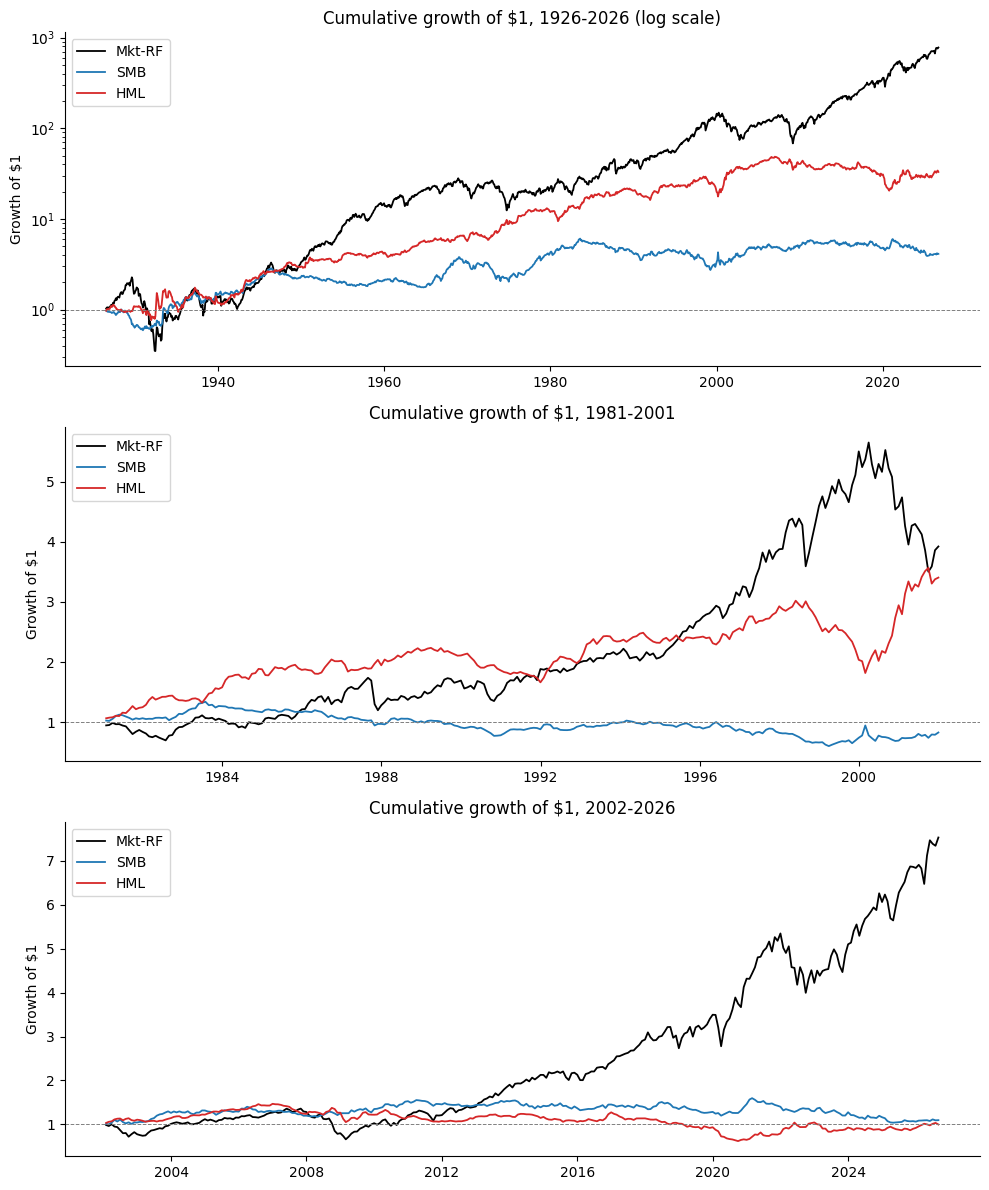

In [6]:
PLOT_SAMPLES = {'1926-2026 (log scale)': ('1926-07', '2026-08'),
                '1981-2001': SAMPLES['1981-2001'], '2002-2026': SAMPLES['2002-2026']}
COLORS = {'Mkt-RF': 'black', 'SMB': 'tab:blue', 'HML': 'tab:red'}

fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for ax, (title, (start, end)) in zip(axes, PLOT_SAMPLES.items()):
    growth = (1 + factors.loc[start:end]).cumprod()
    for f in FACTORS:
        ax.plot(growth[f], color=COLORS[f], lw=1.3, label=f)
    if 'log' in title:
        ax.set_yscale('log')
    ax.axhline(1, color='grey', lw=0.7, ls='--')
    ax.set_title(f'Cumulative growth of $1, {title}')
    ax.set_ylabel('Growth of $1')
    ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT / 'q4_cumulative_returns.png', dpi=160)
plt.show()

Each line is the growth of \$1 invested in the factor's excess (long-short) return, $\prod_t (1+r_t)$.

- **1981–2001:** the market grows \$1 to about \$3.9 and `HML` to about \$3.4. `HML` rises fairly steadily until 1997, falls during the late-1990s growth rally, and then jumps back in 2000–2001. `SMB` peaks in 1983, slides until 1999, and ends below \$1 (about \$0.83).
- **2002–2026:** the market grows \$1 to about \$7.5. `SMB` (about \$1.10) and `HML` (about \$1.00) end almost where they started. `HML` peaks at the end of 2006, falls until 2020, and then partly recovers.

## 5. Were the factors valuable?

**Were all three factors valuable in 1981–2001?** No. Market and value were, but size was not.
- `HML` had the best Sharpe ratio of the three (0.59) and a 6.4% premium. It was also negatively correlated with the market (−0.53), so it diversified market risk.
- `Mkt-RF` earned 7.8% with a Sharpe ratio of 0.50.
- `SMB` earned nothing (−0.2%, Sharpe ≈ 0). \$1 in size ended at about \$0.83 after 21 years.

**And post-2001?** Only the market was valuable. `SMB` and `HML` earned 0.8% and 0.6% a year with Sharpe ratios below 0.1, and both end the period roughly where they started. The market earned 9.4% with a Sharpe ratio of 0.62.

**Would we advise DFA to keep emphasizing all three factors?** Not equally.
- **Market:** yes. It is the only premium that held up in every subsample.
- **Value:** keep it, but with lower expectations. It earned 5.0% and 6.4% in the first two subsamples, and 25 flat years are not conclusive for a factor with about 11% volatility. Still, clients should expect long periods of zero or negative value returns.
- **Size:** de-emphasize it. Almost all of its premium comes from before 1981, and it has been about zero for the 45 years since. The size effect became widely known around 1981 (Banz), and it may have been competed away after that.

# Section 3 — CAPM

## Data

- Test assets: the 25 size/book-to-market portfolios, converted to excess returns with $\tilde r^i_t = r^i_t - r^f_t$ using `RF` from the `factors` sheet. Names are `ME1`–`ME5` for size (small to big) and `BM1`–`BM5` for book-to-market (growth to value), with `SMALL`/`BIG` and `LoBM`/`HiBM` marking the corners.
- Market: `Mkt-RF`.
- Sample: January 1981 to August 2026 for the whole section.

In [7]:
SAMPLE_3 = ('1981-01', '2026-08')
all_factors = pd.read_excel(DFA_FILE, sheet_name='factors', index_col='Date')
all_factors.index = pd.to_datetime(all_factors.index)
portfolios = pd.read_excel(DFA_FILE, sheet_name='portfolios (total returns)', index_col='Date')
portfolios.index = pd.to_datetime(portfolios.index)

rf = all_factors['RF'].loc[SAMPLE_3[0]:SAMPLE_3[1]]
mkt = all_factors['Mkt-RF'].loc[SAMPLE_3[0]:SAMPLE_3[1]]
port_excess = portfolios.loc[SAMPLE_3[0]:SAMPLE_3[1]].sub(rf, axis=0)
assert port_excess.index.equals(mkt.index)
print(f'{len(port_excess)} months, {port_excess.shape[1]} portfolios: '
      f'{port_excess.index[0]:%Y-%m} to {port_excess.index[-1]:%Y-%m}')

548 months, 25 portfolios: 1981-01 to 2026-08


## 1. Summary statistics

In [8]:
port_stats = performance_stats(port_excess)
port_stats.index.name = 'portfolio'
port_stats.to_csv(OUTPUT / 's3_q1_portfolio_stats.csv')
display(port_stats.style.format({'Mean': '{:.2%}', 'Vol': '{:.2%}', 'Sharpe': '{:.2f}', 'VaR(.05)': '{:.2%}'}))

,Mean,Vol,Sharpe,VaR(.05)
portfolio,,,,
SMALL LoBM,1.63%,27.11%,0.06,-12.26%
ME1 BM2,9.28%,23.43%,0.40,-9.57%
ME1 BM3,9.62%,20.03%,0.48,-8.44%
ME1 BM4,11.68%,19.26%,0.61,-7.72%
SMALL HiBM,13.05%,20.67%,0.63,-8.72%
ME2 BM1,6.61%,24.37%,0.27,-10.25%
ME2 BM2,10.51%,20.49%,0.51,-8.35%
ME2 BM3,11.10%,18.64%,0.60,-7.90%
ME2 BM4,10.97%,18.10%,0.61,-7.50%


## 2. CAPM time-series regressions

For each portfolio, $\tilde r^i_t = \alpha^i + \beta^{i,\text{mkt}}\tilde r^{\text{mkt}}_t + \epsilon^i_t$.
- Treynor ratio: $\text{TR}^i = \mathbb{E}[\tilde r^i] / \beta^{i,\text{mkt}}$ (annualized mean).
- Information ratio: $\text{IR}^i = \alpha^i / \sigma(\epsilon^i)$, annualized with $\times\sqrt{12}$.
- Alphas are annualized with $\times 12$.

In [9]:
X_mkt = sm.add_constant(mkt.rename('mkt'))
capm_fits = {p: sm.OLS(port_excess[p], X_mkt).fit() for p in port_excess}

capm = pd.DataFrame({p: {
    'Beta': fit.params['mkt'],
    'Treynor': port_excess[p].mean() * ANN / fit.params['mkt'],
    'Alpha': fit.params['const'] * ANN,
    'Info ratio': fit.params['const'] / fit.resid.std(ddof=1) * np.sqrt(ANN),
} for p, fit in capm_fits.items()}).T
capm.index.name = 'portfolio'
capm.to_csv(OUTPUT / 's3_q2_capm.csv')

mae = capm['Alpha'].abs().mean()
print(f'MAE of alphas (annualized): {mae:.2%}')
print(f'Market mean excess return (annualized): {mkt.mean() * ANN:.2%}')
display(capm.style.format({'Beta': '{:.2f}', 'Treynor': '{:.2%}', 'Alpha': '{:.2%}', 'Info ratio': '{:.2f}'}))

MAE of alphas (annualized): 2.22%
Market mean excess return (annualized): 8.65%


,Beta,Treynor,Alpha,Info ratio
portfolio,,,,
SMALL LoBM,1.36,1.19%,-10.17%,-0.60
ME1 BM2,1.16,8.00%,-0.75%,-0.05
ME1 BM3,1.05,9.18%,0.56%,0.05
ME1 BM4,0.97,12.07%,3.32%,0.27
SMALL HiBM,0.99,13.21%,4.50%,0.32
ME2 BM1,1.33,4.96%,-4.92%,-0.38
ME2 BM2,1.14,9.26%,0.69%,0.07
ME2 BM3,1.04,10.71%,2.13%,0.22
ME2 BM4,0.97,11.34%,2.60%,0.26


**If the CAPM were true, what would we expect of the MAE?** It would be zero, apart from sampling error, because every alpha would be zero. We get an MAE of **2.2% a year**, about a quarter of the 8.6% market premium.

**If the CAPM were true, what would be true of the Treynor ratios, alphas, and information ratios?**
- **Alphas** would all be zero.
- **Information ratios** would all be zero, since they are alpha divided by residual volatility.
- **Treynor ratios** would all equal the market's mean excess return (8.6% a year), because $\mathbb{E}[\tilde r^i] = \beta^{i}\,\mathbb{E}[\tilde r^{\text{mkt}}]$.

**What we find.**
- Treynor ratios range from 1.2% (`SMALL LoBM`) to 13.2% (`SMALL HiBM`), far from a common 8.6%.
- The alphas follow book-to-market. The value column (`BM5`) has positive alphas in all five size groups, from 1.9% to 4.5%. The growth column (`BM1`) has negative alphas in four of five size groups. Small growth is the worst at −10.2% a year (IR −0.60).
- Betas are all fairly close to 1 (0.87 to 1.36), so differences in beta can't explain the large spread in mean returns (1.6% to 13.0%).

## 3. Cross-sectional estimation

$$\mathbb{E}[\tilde r^i] = \eta + \beta^{i,\text{mkt}}\lambda_{\text{mkt}} + \upsilon^i$$

The dependent variable is each portfolio's annualized sample mean excess return, and the regressor is its time-series beta from Question 2.

In [10]:
cs_fit = sm.OLS(port_stats['Mean'], sm.add_constant(capm['Beta'])).fit()
cross_section = pd.Series({'R-squared': cs_fit.rsquared, 'eta (annualized)': cs_fit.params['const'],
                           'lambda_mkt (annualized)': cs_fit.params['Beta']})
cross_section.to_csv(OUTPUT / 's3_q3_cross_section.csv', header=['value'])
display(cross_section.to_frame('value').style.format('{:.4f}'))


,value
R-squared,0.2969
eta (annualized),0.2034
lambda_mkt (annualized),-0.1006


**Results.** $R^2 = 0.30$, $\eta = 20.3\%$ a year, and $\lambda_{\text{mkt}} = -10.1\%$ a year.

**If the CAPM were completely accurate:**
- $R^2 = 1$: beta would explain all of the variation in mean returns.
- $\eta = 0$: an asset with zero beta would earn no premium.
- $\lambda_{\text{mkt}} = \mathbb{E}[\tilde r^{\text{mkt}}] = 8.6\%$: the price of beta risk would equal the market premium.

The estimates are far from all three. The slope even has the wrong sign: higher-beta portfolios earned *lower* average returns. This is driven mostly by the high-beta growth portfolios, especially `SMALL LoBM` (beta 1.36, mean 1.6%). The intercept is large and positive, and beta explains less than a third of the spread in means.

## 4. Conclusion

**Do these results support DFA's belief in size and value premia unrelated to the market premium?** For value, yes. For size, not really.
- The CAPM fails on these portfolios. Alphas are large (MAE 2.2%), Treynor ratios vary widely, and the cross-sectional slope on beta is negative rather than 8.6%. So these portfolios earn premia that market beta does not explain.
- The pattern lines up with **value**. High book-to-market portfolios have positive alphas in every size group, and growth portfolios have mostly negative alphas.
- The pattern does **not** line up with **size**. The smallest-size row has both the largest positive alpha (`SMALL HiBM`, 4.5%) and the most negative (`SMALL LoBM`, −10.2%). Small stocks earn a premium only when they are also value stocks. This matches Section 2, where `SMB` earned about zero after 1980.

## 5. Joint test of alphas

$$H = T\left[1 + (\text{SR}_{\text{mkt}})^2\right]^{-1}\boldsymbol{\alpha}'\boldsymbol{\Sigma}_\epsilon^{-1}\boldsymbol{\alpha} \sim \chi^2_{n}, \qquad n = 25$$

Here $\boldsymbol\alpha$ holds the monthly alphas, $\boldsymbol\Sigma_\epsilon$ is the covariance matrix of the residuals, and $\text{SR}_{\text{mkt}}$ is the monthly Sharpe ratio of `Mkt-RF`.

In [11]:
alpha_m = np.array([fit.params['const'] for fit in capm_fits.values()])
resid = pd.DataFrame({p: fit.resid for p, fit in capm_fits.items()})
sigma_eps = resid.cov().values
sr_mkt = mkt.mean() / mkt.std(ddof=1)
T, n = len(mkt), len(alpha_m)

H = T / (1 + sr_mkt**2) * alpha_m @ np.linalg.solve(sigma_eps, alpha_m)
n_significant = sum(abs(fit.tvalues['const']) > 1.96 for fit in capm_fits.values())

joint_test = pd.Series({'T': T, 'n': n, 'SR_mkt (monthly)': sr_mkt, 'H': H,
                        'p-value': chi2.sf(H, n), '5% critical value': chi2.ppf(0.95, n),
                        'Individual alphas with |t| > 1.96': n_significant})
joint_test.to_csv(OUTPUT / 's3_q5_joint_test.csv', header=['value'])
display(joint_test.to_frame('value'))

,value
T,5.480000e+02
n,2.500000e+01
SR_mkt (monthly),1.615175e-01
H,1.315226e+02
p-value,1.961197e-16
5% critical value,3.765248e+01
Individual alphas with |t| > 1.96,4.000000e+00


**Results.** $H = 131.5$, against a 5% critical value of 37.7 for $\chi^2_{25}$. The p-value is about $2\times10^{-16}$, so we strongly reject the CAPM. Individually, 4 of the 25 alphas are significant at 5%.

**Which is the stricter test?** Checking whether *any* of the 25 individual t-tests is significant is the stricter, harsher standard for the CAPM.
- Each t-test has a 5% false-rejection rate. With 25 tests, the chance that at least one rejects by luck is much higher than 5% (about $1 - 0.95^{25} \approx 72\%$ if the tests were independent). So the CAPM would "fail" often even if it were true.
- $H$ tests all 25 alphas at once, with the stated 5% size. It also accounts for the correlation between residuals through $\boldsymbol\Sigma_\epsilon$. So $H$ is the proper test. It can reject even when no single alpha is significant, and it can fail to reject when one alpha looks significant by chance.

**How does $H$ relate to whether $\tilde r^{\text{mkt}}$ spans the tangency portfolio?** $H$ measures how much the test assets improve on the market's Sharpe ratio:

$$\boldsymbol\alpha'\boldsymbol\Sigma_\epsilon^{-1}\boldsymbol\alpha = \text{SR}_{\tan}^2 - \text{SR}_{\text{mkt}}^2,$$

where $\text{SR}_{\tan}$ is the Sharpe ratio of the tangency portfolio built from the market and the 25 portfolios. If the market spans the tangency portfolio, adding the portfolios doesn't raise the maximum Sharpe ratio, all alphas are zero, and $H = 0$. A large $H$ means the market is not mean-variance efficient. Here the 25 portfolios clearly add Sharpe ratio beyond the market.